In [20]:
import numpy as np

class LinearRegression:

    def __init__(self, epochs=1000, lr=0.01, batch_size=32):
        # Parameters
        self.w = None
        self.b = None
        # Hyperparameters
        self.epochs = epochs
        self.lr = lr
        self.batch_size = batch_size

    def gradient_descent(self, X, y):
        n, d = X.shape
        w = np.zeros(d)
        b = 0
        for epoch in range(self.epochs):
            y_pred = X @ w + b
            error = y_pred - y
            dw = (2/n) * (X.T @ error)
            db = (2/n) * np.sum(error)
            w = w - self.lr * dw
            b = b - self.lr * db
        return w, b

    def minibatch_gradient_descent(self, X, y):
        n, d = X.shape
        w = np.zeros(d)
        b = 0
        for epoch in range(self.epochs):
            # Shuffle data for each epoch
            indices = np.random.permutation(n)
            X_shuffled = X[indices]
            y_shuffled = y[indices]
            # Iterate over mini-batches
            for i in range(0, n, self.batch_size):
                X_batch = X_shuffled[i:i+self.batch_size]
                y_batch = y_shuffled[i:i+self.batch_size]
                y_pred = X_batch @ w + b
                error = y_pred - y_batch
                dw = (2/len(X_batch)) * (X_batch.T @ error)
                db = (2/len(X_batch)) * np.sum(error)
                w = w - self.lr * dw
                b = b - self.lr * db
        return w, b

    def stochastic_gradient_descent(self, X, y):
        n, d = X.shape
        w = np.zeros(d)
        b = 0
        for epoch in range(self.epochs):
            # Shuffle data for each epoch
            indices = np.random.permutation(n)
            X_shuffled = X[indices]
            y_shuffled = y[indices]
            # Update on a single sample at a time
            for i in range(n):
                X_i = X_shuffled[i:i+1]
                y_i = y_shuffled[i:i+1]
                y_pred = X_i @ w + b
                error = y_pred - y_i
                dw = 2 * (X_i.T @ error)
                db = 2 * np.sum(error)
                w = w - self.lr * dw
                b = b - self.lr * db
        return w, b

    def closed_form_solution(self, X, y):
        n, d = X.shape
        # Augment X with a column of ones so the bias is solved for jointly with the weights
        X_aug = np.hstack([np.ones((n, 1)), X])
        # Normal equation: theta = (X^T X)^-1 X^T y, via pinv for numerical stability
        theta = np.linalg.pinv(X_aug.T @ X_aug) @ X_aug.T @ y
        b = theta[0]
        w = theta[1:]
        return w, b

    def fit(self, X, y):
        self.w, self.b = self.closed_form_solution(X, y)

    def predict(self, X):
        return X @ self.w + self.b

Estimated weights: [2.95402268]
Estimated bias: 5.021509615754668


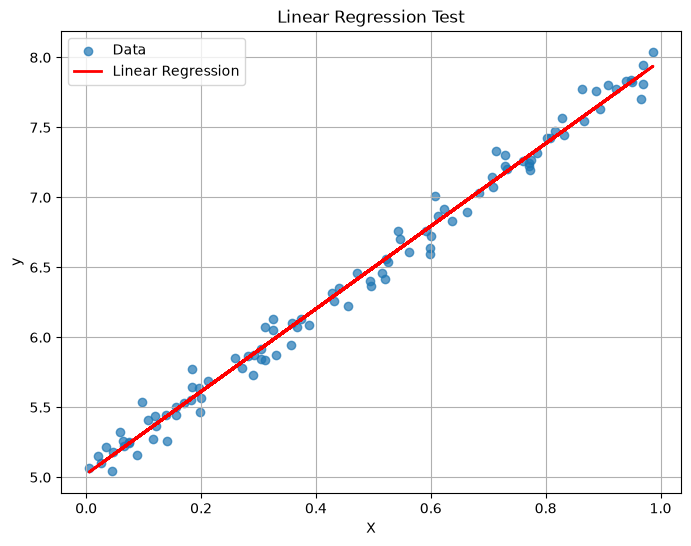

In [21]:
import matplotlib.pyplot as plt

# Generate synthetic linear data
np.random.seed(42)
X = np.random.rand(100, 1)
y = 3 * X[:, 0] + 5 + 0.1 * np.random.randn(100)

# Train the model
model = LinearRegression()
model.fit(X, y)
y_pred = model.predict(X)

print(f"Estimated weights: {model.w}")
print(f"Estimated bias: {model.b}")

# Plot the results
plt.figure(figsize=(8, 6))
plt.scatter(X[:, 0], y, label="Data", alpha=0.7)
plt.plot(X[:, 0], y_pred, color="red", linewidth=2, label="Linear Regression")
plt.xlabel("X")
plt.ylabel("y")
plt.title("Linear Regression Test")
plt.legend()
plt.grid(True)
plt.show()